# Sistema especialista para identificar golpes
**UDF — Ciência da Computação | Inteligência Artificial e LFA**  
**Professora:** Kadidja Valéria

O objetivo do trabalho é ajudar pessoas que recebem mensagens ou ligações suspeitas em nome de bancos e operadoras. A árvore de decisão classifica o texto em `golpe` ou `legitimo`. Depois, o sistema especialista utiliza essa previsão e as respostas do usuário para recomendar medidas de segurança.

O projeto utiliza dados simulados e não verifica a identidade de quem entrou em contato. Não informe dados pessoais ou bancários reais. Execute as células na ordem.

### Estudo inicial
- Aprendizado de máquina: o modelo aprende padrões a partir de exemplos.
- Aprendizado supervisionado: os exemplos possuem respostas conhecidas (rótulos).
- Atributos: informações usadas como entrada; rótulo: categoria esperada.
- Classificação prevê categorias; regressão prevê valores numéricos.
- Separar treino e teste permite avaliar o modelo em exemplos não usados no treinamento.

## 1. Preparar o ambiente
Usamos Python, pandas, matplotlib e scikit-learn. Se alguma biblioteca estiver ausente, instale-a com `%pip install pandas matplotlib scikit-learn`.

In [3]:
"""
Sistema Especialista com Aprendizado Supervisionado
Triagem de golpes de falsa central de atendimento (banco/operadora)
====================================================================
Arquitetura híbrida em duas fases:
  FASE 1 (machine learning): árvore de decisão lê o TEXTO da mensagem e gera o
          fato dinâmico "ml_golpe".
  FASE 2 (sistema especialista): Base de Conhecimento + Memória de Trabalho +
          Motor de Inferência (encadeamento para frente e para trás) combinam esse
          fato às respostas do usuário e entregam: grau de suspeita (fatores de
          certeza), tipo de golpe e plano de ação, com explicação.

Este módulo é a fonte principal; o notebook contém uma cópia sincronizada para uso autônomo no Colab.
Use:  python src/sistema_golpes.py   (consulta interativa no terminal)

Aviso: dados de treino SIMULADOS; ferramenta educacional de apoio. Não substitui o
atendimento oficial do banco ou da operadora.
"""
# Importação das bibliotecas necessárias
import re                                   # re: expressões regulares (extração de atributos do texto)
import unicodedata                          # unicodedata: remove acentos para comparar palavras
from dataclasses import dataclass, field    # dataclass: cria classes de dados de forma enxuta
from typing import Callable, Optional       # tipos usados nas anotações das funções

# pandas: manipulação e análise de dados estruturados
import pandas as pd
# train_test_split: divisão em treino e teste; StratifiedKFold/cross_val_score: validação cruzada
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
# DecisionTreeClassifier: algoritmo de árvore de decisão para classificação
from sklearn.tree import DecisionTreeClassifier
# Métricas de avaliação: acurácia e matriz de confusão
from sklearn.metrics import accuracy_score, confusion_matrix

import matplotlib.pyplot as plt
from sklearn.tree import export_text, plot_tree
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


## 2. Dataset rotulado
São 100 mensagens fictícias (50 de cada classe). Foram mantidos 40 exemplos revisados e acrescentados 60 com auxílio de IA. A classificação de referência vem do cenário imaginado, não de uma investigação real.

O texto é convertido em nove atributos: contagens de links, termos de urgência, dados sensíveis, verbos de pedido, exclamações, proporção de maiúsculas e três indicadores de pedido ou aviso. O rótulo `perfil` fica separado das entradas.

In [4]:
# Mensagens fictícias (texto, rótulo), preparadas para o trabalho com auxílio de IA.
MENSAGENS_SIMULADAS = [
    # ---------------- golpes (20) ----------------
    ("URGENTE! Sua conta foi bloqueada. Regularize agora em https://banco-seguro.example.invalid/login e informe sua senha.", "golpe"),
    ("Identificamos uma compra suspeita no seu cartão. Para cancelar, informe o código enviado por SMS imediatamente.", "golpe"),
    ("Sou da central de segurança do Banco Exemplo. Sua conta foi invadida. Faça um Pix para uma conta segura agora para proteger seu saldo.", "golpe"),
    ("Seu cartão foi clonado. Um motoboy irá buscá-lo hoje. Corte o cartão sem danificar o chip e informe a senha.", "golpe"),
    ("Atenção: instale o aplicativo de suporte para liberar o acesso e resolver o bloqueio da sua conta imediatamente.", "golpe"),
    ("Parabéns! Você ganhou aumento de limite! Clique em https://limite-premiado.example.invalid e confirme seu CPF e senha.", "golpe"),
    ("Operadora Exemplo: seu chip será suspenso hoje. Atualize seus dados em https://chip-ativo.example.invalid e informe o código recebido.", "golpe"),
    ("Cashback de R$ 500 liberado! Pague a taxa de liberação de R$ 29,90 via Pix para receber seu prêmio.", "golpe"),
    ("Detectamos um novo aparelho conectado à sua conta. Confirme sua senha e o token para cancelar a operação agora.", "golpe"),
    ("Seu Pix de R$ 3.200 foi bloqueado. Transferência pendente: regularize o pagamento em 1 hora para evitar multa.", "golpe"),
    ("BANCO EXEMPLO: SUA CONTA SERÁ ENCERRADA HOJE!!! ACESSE https://exemplo-banco.example.invalid E CONFIRME SEUS DADOS AGORA!!!", "golpe"),
    ("Houve tentativa de fraude. Para sua segurança, passe o código de 6 dígitos que enviamos por SMS.", "golpe"),
    ("Aqui é do setor antifraude. Precisamos validar seu CPF e a senha do cartão para estornar a compra indevida.", "golpe"),
    ("Seu cadastro expira hoje. Clique no link para atualizar e evitar o bloqueio do cartão: www.atualiza-cadastro.exemplo.com/app", "golpe"),
    ("Devolução disponível: informe seu token e faça uma transferência de validação de R$ 1,00.", "golpe"),
    ("Atendimento da Operadora Exemplo: você tem bônus de internet. Digite o código recebido para ativar agora.", "golpe"),
    ("Seu cartão foi bloqueado por segurança. Entregue o cartão ao nosso portador e informe a senha para desbloquear.", "golpe"),
    ("Compra de R$ 4.890 em andamento. Se não reconhece, ligue já para [número fictício] e informe seu CPF e senha.", "golpe"),
    ("Boleto de regularização pendente. Pague agora via Pix para liberar seu limite. Chave aleatória abaixo.", "golpe"),
    ("Seu acesso será suspenso. Instale o app e informe o token para manter a conta ativa.", "golpe"),
    # ---------------- legítimas (20) ----------------
    ("Compra aprovada no cartão final 1234, R$ 54,90, em Mercado Exemplo.", "legitimo"),
    ("Sua fatura do cartão já está disponível no aplicativo. Vencimento em 10/12.", "legitimo"),
    ("Seu código de acesso é XXX. Não compartilhe com ninguém. Validade: 5 minutos.", "legitimo"),
    ("Pix recebido de Pessoa Exemplo no valor de R$ 120,00.", "legitimo"),
    ("Lembrete: sua fatura vence amanhã. Pague pelo aplicativo ou pelo internet banking.", "legitimo"),
    ("Olá! Seu pedido saiu para entrega e chega hoje entre 14h e 18h.", "legitimo"),
    ("Sua agência atende de segunda a sexta, das 10h às 16h.", "legitimo"),
    ("Aviso: nunca informe senha ou código por telefone. O banco nunca solicita esses dados.", "legitimo"),
    ("Seu extrato de novembro está disponível. Acesse o aplicativo para consultar.", "legitimo"),
    ("Transferência agendada para 20/11 no valor de R$ 300,00 realizada com sucesso.", "legitimo"),
    ("Seu plano foi renovado. Franquia de 20 GB disponível até 15/12.", "legitimo"),
    ("Confirmação: seu limite foi ajustado conforme solicitado por você no aplicativo.", "legitimo"),
    ("Código de verificação XXX. Se não foi você, ignore esta mensagem.", "legitimo"),
    ("O prazo para declarar o imposto termina em breve. Veja o guia no site oficial https://gov.example.invalid/guia", "legitimo"),
    ("Oferta para clientes: 5% de desconto na primeira compra. Válido até domingo.", "legitimo"),
    ("Sua senha foi alterada com sucesso. Se não reconhece, ligue para o número do verso do cartão.", "legitimo"),
    ("Atualização do app disponível! Atualize pela loja oficial quando puder.", "legitimo"),
    ("Seu cartão foi enviado e chega em até 7 dias úteis. Acompanhe pelo aplicativo.", "legitimo"),
    ("Pagamento do boleto confirmado. Obrigado!", "legitimo"),
    ("Informe-nos sua opinião: avalie o atendimento em até 3 dias no aplicativo.", "legitimo"),
    # Outros 60 exemplos simulados.
    ('Aqui é do banco. Precisamos que você leia os números que chegaram por mensagem para cancelar uma compra.', 'golpe'),
    ('A central solicita a entrega do cartão ao mensageiro que está a caminho.', 'golpe'),
    ('Mova o saldo para a chave indicada pelo atendimento para proteger a conta.', 'golpe'),
    ('Para verificar o dispositivo, permita que eu veja sua tela pelo programa de suporte.', 'golpe'),
    ('Seu prêmio exige uma tarifa antecipada de liberação.', 'golpe'),
    ('Confirme os dados do cartão na página encaminhada pelo atendimento.', 'golpe'),
    ('Oi, sou do banco, me manda o cod que apareceu no celular pfv.', 'golpe'),
    ('Para validar o chip, mande o PIN pelo chat.', 'golpe'),
    ('Para cancelar a cobrança, precisamos acessar seu aparelho.', 'golpe'),
    ('Seu cartão precisa ser devolvido ao coletor da agência.', 'golpe'),
    ('Envie uma foto dos dois lados do cartão para a análise.', 'golpe'),
    ('O reembolso depende de um depósito prévio para o analista.', 'golpe'),
    ('Para proteger a poupança, envie o saldo para a conta que indicamos.', 'golpe'),
    ('Compartilhe a tela enquanto abre o aplicativo bancário.', 'golpe'),
    ('Receba seu bônus pagando uma taxa de cadastro ao representante.', 'golpe'),
    ('Precisamos da sequência de autenticação para validar sua identidade.', 'golpe'),
    ('Envie a senha do portal da operadora pelo WhatsApp.', 'golpe'),
    ('Cadastre o dispositivo do atendimento como autorizado na sua conta.', 'golpe'),
    ('Entregue o chip ao funcionário externo para validar a troca.', 'golpe'),
    ('Precisamos da palavra secreta da conta para confirmar o cadastro.', 'golpe'),
    ('Passe o código de recuperação do aplicativo para a central.', 'golpe'),
    ('Instale o programa de suporte para que o técnico controle a tela.', 'golpe'),
    ('Você receberá o benefício depois de uma transferência de confirmação.', 'golpe'),
    ('Aprove a operação que aparece na tela para cancelar a cobrança.', 'golpe'),
    ('Faça o pagamento antecipado para desfazer o empréstimo que apareceu na conta.', 'golpe'),
    ('Preencha as credenciais no formulário encaminhado pelo chat.', 'golpe'),
    ('Escaneie o QR para enviar o saldo à conta de proteção.', 'golpe'),
    ('Um representante vai recolher seu cartão danificado em casa.', 'golpe'),
    ('Forneça a chave de recuperação da conta digital ao atendente.', 'golpe'),
    ('Desative a proteção do aparelho para que o suporte faça a verificação.', 'golpe'),
    ('Alerta de segurança: não envie códigos de confirmação a terceiros.', 'legitimo'),
    ('Sua fatura vence hoje. Consulte o valor diretamente no aplicativo que já utiliza.', 'legitimo'),
    ('A instituição comunica manutenção programada para esta madrugada.', 'legitimo'),
    ('O cartão final XXXX foi utilizado em uma compra que você pode consultar no aplicativo.', 'legitimo'),
    ('Não informe sua senha a quem entrar em contato por telefone.', 'legitimo'),
    ('Seu limite permanece o mesmo. Consulte os detalhes no aplicativo.', 'legitimo'),
    ('A operadora informa que sua franquia mensal foi renovada.', 'legitimo'),
    ('Se você não reconhece a compra, abra o aplicativo oficial por conta própria.', 'legitimo'),
    ('Atenção! O prazo da fatura termina hoje; não responda com dados pessoais.', 'legitimo'),
    ('Oi! Seu pacote de internet foi renovado com sucesso.', 'legitimo'),
    ('O extrato está disponível para consulta na área autenticada.', 'legitimo'),
    ('A solicitação de segunda via que você iniciou foi concluída.', 'legitimo'),
    ('Seu cartão virtual foi desativado conforme sua solicitação.', 'legitimo'),
    ('Nunca permita acesso remoto a alguém que ligue em nome do banco.', 'legitimo'),
    ('O pagamento agendado foi processado; confira o comprovante no aplicativo.', 'legitimo'),
    ('Código de verificação fictício: XXX. Não informe esse código por telefone.', 'legitimo'),
    ('Seu plano mensal será atualizado na próxima data de renovação.', 'legitimo'),
    ('A agência terá horário especial no feriado.', 'legitimo'),
    ('Seu cadastro foi atualizado por você na área autenticada.', 'legitimo'),
    ('Seu depósito foi registrado; o extrato já reflete a movimentação.', 'legitimo'),
    ('A transferência recebida está disponível no histórico.', 'legitimo'),
    ('Em caso de bloqueio, procure por conta própria o canal oficial.', 'legitimo'),
    ('Sua senha foi redefinida a partir da solicitação feita no aplicativo.', 'legitimo'),
    ('Comunicado: a instituição não recolhe cartões na residência.', 'legitimo'),
    ('Seu protocolo de atendimento já está disponível na área do cliente.', 'legitimo'),
    ('A promoção está descrita na seção de benefícios do aplicativo, sem taxa de adesão.', 'legitimo'),
    ('O serviço de mensagens ficará indisponível durante a manutenção.', 'legitimo'),
    ('Atenção: nunca transfira dinheiro para uma suposta conta segura.', 'legitimo'),
    ('A pesquisa de satisfação é opcional e não solicita informações bancárias.', 'legitimo'),
    ('O pacote adicional que você contratou já está ativo.', 'legitimo'),
]

# Atributos de entrada (X), sem o rótulo.
ATRIBUTOS = ["n_links", "n_urgencia", "n_dados_sensiveis",
             "n_verbos_pedido", "n_exclamacoes", "pct_maiusculas",
             "pedido_credencial", "aviso_preventivo", "pedido_acao_risco"]

# Prefixos de palavras usados na extração de atributos.
TERMOS_URGENCIA = ["urgente", "imediat", "agora", "hoje", "bloque", "ultimas horas",
                   "expira", "suspens", "prazo", "encerrad", "1 hora"]
TERMOS_SENSIVEIS = ["senha", "cvv", "codigo", "token", "cpf", "pix",
                    "transfer", "deposito"]
VERBOS_PEDIDO = ["informe", "envie", "digite", "confirme", "passe", "forneca",
                 "transfira", "instale", "clique", "atualiz", "regulariz",
                 "desbloque", "entregue", "pague", "faca", "corte", "ligue"]
# Expressão regular para reconhecer links.
PADRAO_LINK = re.compile(r"(https?://|www\.|bit\.ly|[a-z0-9-]+\.(?:com|net|org|app|link|top|xyz)\b)")

def normalizar(texto: str) -> str:
    """O QUE FAZ: padroniza o texto para comparação.
    Remove acentos e converte para minúsculas ("Código" -> "codigo").
    POR QUÊ: assim "SENHA", "senha" e "Senha" são tratadas como a mesma palavra."""
    sem_acento = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    return sem_acento.lower()


def _contar_termos(texto_norm: str, termos: list) -> int:
    """Conta QUANTOS termos distintos da lista aparecem no texto (início de palavra)."""
    return sum(1 for t in termos if re.search(r"\b" + re.escape(t), texto_norm))


def extrair_atributos(texto: str) -> dict:
    """O QUE É: a ponte entre texto e machine learning.
    O QUE FAZ: transforma uma mensagem em 9 números (os atributos X) que o
    classificador consegue usar. É a "engenharia de atributos" do projeto."""
    norm = normalizar(texto)
    letras = [c for c in texto if c.isalpha()]
    maiusculas = sum(1 for c in letras if c.isupper())
    aviso = bool(re.search(r"\b(?:nunca|nao)\s+(?:informe|envie|compartilhe|permita|transfira|responda)", norm))
    pedido = bool(re.search(r"\b(?:ped(?:iu|e|iram)|solicit\w*|exig\w*|informe|envie|confirme|digite|manda|passe|leia)\b", norm))
    credencial = bool(re.search(r"\b(?:senha|codigo|token|cvv|pin|credencia\w*|palavra secreta|cod)\b", norm))
    acao_risco = bool(re.search(r"acesso remoto|compartilh\w* a tela|conta segura|entreg\w* o cartao|recolh\w* cart|taxa|tarifa antecipada|transferencia|deposito previo", norm))
    return {
        "n_links": sum(1 for tok in norm.split() if PADRAO_LINK.search(tok)),
        "n_urgencia": _contar_termos(norm, TERMOS_URGENCIA),
        "n_dados_sensiveis": _contar_termos(norm, TERMOS_SENSIVEIS),
        "n_verbos_pedido": _contar_termos(norm, VERBOS_PEDIDO),
        "n_exclamacoes": texto.count("!"),
        "pct_maiusculas": round(100 * maiusculas / len(letras), 1) if letras else 0.0,
        "pedido_credencial": int(pedido and credencial and not aviso),
        "aviso_preventivo": int(aviso),
        "pedido_acao_risco": int(acao_risco and not aviso),
    }


def construir_dataset(mensagens: list = MENSAGENS_SIMULADAS) -> pd.DataFrame:
    """O QUE FAZ: monta o DataFrame de treino: texto + 9 atributos + rótulo `perfil`.
    Cada mensagem passa por `extrair_atributos`, garantindo que treino e uso real
    calculem os atributos exatamente do mesmo jeito."""
    linhas = []
    for texto, perfil in mensagens:
        linhas.append({"texto": texto, **extrair_atributos(texto), "perfil": perfil})
    return pd.DataFrame(linhas)

dados = construir_dataset()
print(dados["perfil"].value_counts())
display(dados.head(8))

perfil
golpe       50
legitimo    50
Name: count, dtype: int64


,texto,n_links,n_urgencia,n_dados_sensiveis,n_verbos_pedido,n_exclamacoes,pct_maiusculas,pedido_credencial,aviso_preventivo,pedido_acao_risco,perfil
0,URGENTE! Sua conta foi bloqueada. Regularize a...,1,3,1,2,1,9.5,1,0,0,golpe
1,Identificamos uma compra suspeita no seu cartã...,0,1,1,1,0,5.4,1,0,0,golpe
2,Sou da central de segurança do Banco Exemplo. ...,0,1,1,1,0,5.6,0,0,1,golpe
3,Seu cartão foi clonado. Um motoboy irá buscá-l...,0,1,1,2,0,3.5,1,0,0,golpe
4,Atenção: instale o aplicativo de suporte para ...,0,2,0,1,0,1.1,0,0,0,golpe
5,Parabéns! Você ganhou aumento de limite! Cliqu...,1,0,2,2,2,6.3,1,0,0,golpe
6,Operadora Exemplo: seu chip será suspenso hoje...,1,2,1,2,0,2.8,1,0,0,golpe
7,Cashback de R$ 500 liberado! Pague a taxa de l...,0,0,1,1,1,7.2,0,0,1,golpe


## 3. Treinamento e avaliação
A divisão é de 75% para treino e 25% para teste, com `random_state=42` e estratificação. A árvore tem profundidade máxima 3 e pelo menos dois registros por folha, para limitar a complexidade. `fit()` ajusta o modelo e `predict()` classifica os exemplos reservados. Também usamos validação cruzada.

Treino: 75 | Teste: 25
Acurácia de teste: 60.0%; CV: 62.0% ± 4.0%
              precision    recall  f1-score   support

       golpe       0.59      0.77      0.67        13
    legitimo       0.62      0.42      0.50        12

    accuracy                           0.60        25
   macro avg       0.61      0.59      0.58        25
weighted avg       0.61      0.60      0.59        25



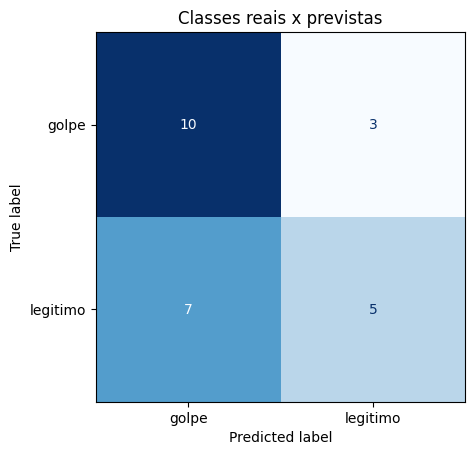

|--- pedido_credencial <= 0.50
|   |--- pct_maiusculas <= 2.50
|   |   |--- aviso_preventivo <= 0.50
|   |   |   |--- class: golpe
|   |   |--- aviso_preventivo >  0.50
|   |   |   |--- class: legitimo
|   |--- pct_maiusculas >  2.50
|   |   |--- n_dados_sensiveis <= 1.50
|   |   |   |--- class: legitimo
|   |   |--- n_dados_sensiveis >  1.50
|   |   |   |--- class: golpe
|--- pedido_credencial >  0.50
|   |--- pct_maiusculas <= 2.10
|   |   |--- class: golpe
|   |--- pct_maiusculas >  2.10
|   |   |--- class: golpe



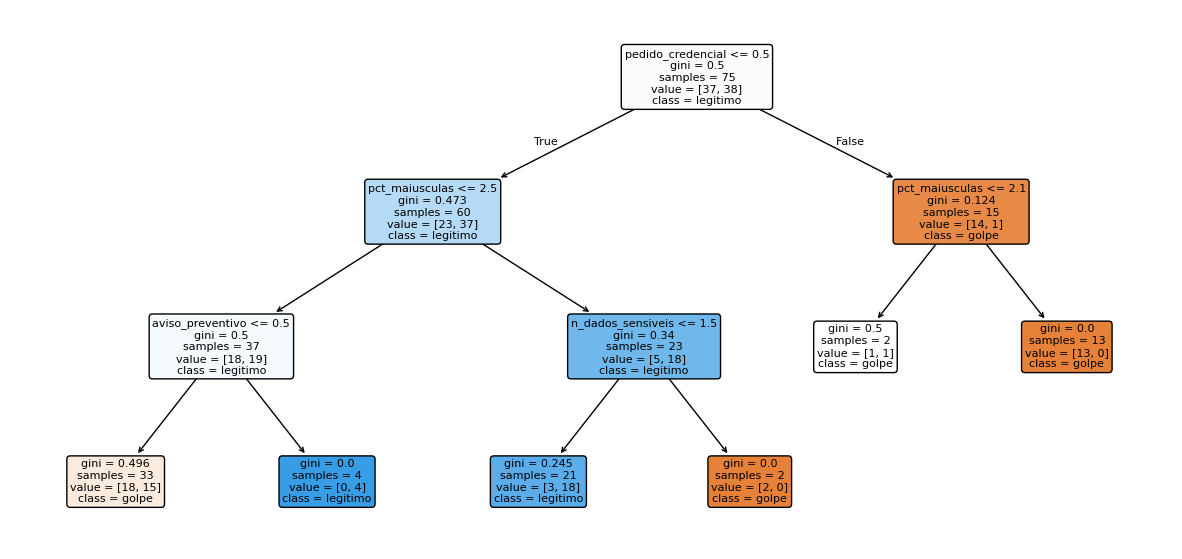

,texto,perfil,previsto
33,O prazo para declarar o imposto termina em bre...,legitimo,golpe
84,O pagamento agendado foi processado; confira o...,legitimo,golpe
39,Informe-nos sua opinião: avalie o atendimento ...,legitimo,golpe
27,Aviso: nunca informe senha ou código por telef...,legitimo,golpe
7,Cashback de R$ 500 liberado! Pague a taxa de l...,golpe,legitimo
96,O serviço de mensagens ficará indisponível dur...,legitimo,golpe
10,BANCO EXEMPLO: SUA CONTA SERÁ ENCERRADA HOJE!!...,golpe,legitimo
77,"Se você não reconhece a compra, abra o aplicat...",legitimo,golpe
18,Boleto de regularização pendente. Pague agora ...,golpe,legitimo
93,Comunicado: a instituição não recolhe cartões ...,legitimo,golpe


In [5]:
@dataclass
class ResultadoTreino:
    """O QUE É: um "pacote" com tudo que saiu do treinamento (modelo, divisões
    treino/teste, previsões e métricas), para podermos exibir e reutilizar."""
    modelo: DecisionTreeClassifier
    X_treino: pd.DataFrame
    X_teste: pd.DataFrame
    y_treino: pd.Series
    y_teste: pd.Series
    previsoes: object
    acuracia: float
    classes: list
    matriz: object
    cv_media: float
    cv_desvio: float


def treinar_modelo(dados: pd.DataFrame, test_size: float = 0.25,
                   random_state: int = 42, max_depth: int = 3) -> ResultadoTreino:
    """O QUE FAZ: executa todo o fluxo de aprendizado supervisionado.
      1) separa X (atributos) e y (rótulo);
      2) divide em treino e teste (estratificado e reproduzível);
      3) treina uma árvore de decisão com profundidade limitada (evita overfitting);
      4) avalia no teste: acurácia e matriz de confusão;
      5) valida por validação cruzada (verificação extra de estabilidade)."""
    X = dados[ATRIBUTOS]          # atributos (o rótulo NÃO entra aqui)
    y = dados["perfil"]           # rótulo (resposta conhecida)

    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y)

    modelo = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=2,
                                    random_state=random_state)
    modelo.fit(X_treino, y_treino)                   # aprende SOMENTE com o treino
    previsoes = modelo.predict(X_teste)              # prevê o conjunto de teste

    classes = ["golpe", "legitimo"]
    matriz = confusion_matrix(y_teste, previsoes, labels=classes)

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=2,
                               random_state=random_state), X, y, cv=cv)

    return ResultadoTreino(modelo, X_treino, X_teste, y_treino, y_teste, previsoes,
                           float(accuracy_score(y_teste, previsoes)), classes, matriz,
                           float(scores.mean()), float(scores.std()))

# ----------------------------------------------------------------------
# Parâmetros do sistema
# ----------------------------------------------------------------------

res = treinar_modelo(dados)
X = dados[ATRIBUTOS]; y = dados['perfil']
print('Treino:', len(res.X_treino), '| Teste:',len(res.X_teste))
print(f'Acurácia de teste: {res.acuracia:.1%}; CV: {res.cv_media:.1%} ± {res.cv_desvio:.1%}')
print(classification_report(res.y_teste,res.previsoes,labels=res.classes,zero_division=0))
ConfusionMatrixDisplay(res.matriz,display_labels=res.classes).plot(cmap='Blues',colorbar=False)
plt.title('Classes reais x previstas'); plt.show()
print(export_text(res.modelo,feature_names=ATRIBUTOS))
plt.figure(figsize=(15,7)); plot_tree(res.modelo,feature_names=ATRIBUTOS,class_names=list(res.modelo.classes_),filled=True,rounded=True,fontsize=8); plt.show()
erros = dados.loc[res.y_teste.index].copy(); erros['previsto']=res.previsoes
display(erros.loc[erros.perfil != erros.previsto,['texto','perfil','previsto']])

### Interpretação dos resultados
No ambiente testado, a árvore acertou 15 de 25 mensagens (60%). Três golpes não foram detectados e sete mensagens legítimas foram classificadas como golpe. Na matriz, as linhas representam as classes reais e as colunas as previstas. Na árvore, `gini` indica impureza, `samples` indica quantidade de exemplos e `value` indica a distribuição das classes.

Os resultados podem variar conforme a versão das bibliotecas. A amostra pequena e simulada não permite afirmar que o modelo funciona em situações reais.

## 4. Base de conhecimento e motor de inferência
A base guarda as regras SE–ENTÃO. A memória de trabalho guarda fatos e conclusões da consulta. O motor aplica as regras sem depender do assunto específico. O encadeamento para frente parte dos fatos; o encadeamento para trás investiga uma hipótese e pergunta o que falta.

Os fatores de certeza (CF) são pesos heurísticos, não probabilidades. Respostas desconhecidas não equivalem a respostas negativas. Quando regras reutilizam o mesmo suporte, o motor evita acumular automaticamente suas contribuições.

In [6]:
LIMIAR = 0.2          # evidência mínima para considerar um fato "verdadeiro"
NIVEL_ALTO = 0.7      # suspeita >= 0.7  -> nível ALTO
NIVEL_MODERADO = 0.4  # suspeita >= 0.4  -> nível MODERADO
MIN_INFO = 4          # mínimo de sinais respondidos para concluir "baixo risco"
EVIDENCIA_MIN_REGRAS = 0.2   # suspeita mínima vinda SÓ das regras para o texto poder elevar o nível

# De onde vem o CRITÉRIO de cada regra (justificativa da origem)
FONTES = {
    "FEB": "Orientações públicas da Febraban (campanha 'Pare & Pense #Pode ser Golpe' e dicas antigolpe)",
    "BCB": "Banco Central do Brasil (Mecanismo Especial de Devolução - MED do Pix)",
    "HEUR": "Heurística do autor, a validar com especialista",
    "ML": "Modelo de aprendizado de máquina (Fase 1)",
}


def combinar(a: float, b: float) -> float:
    """O QUE FAZ: combina dois fatores de certeza que apoiam a MESMA conclusão
    (fórmula do MYCIN). O resultado fica sempre entre -1 e +1."""
    if a >= 0 and b >= 0:
        return a + b * (1 - a)
    if a <= 0 and b <= 0:
        return a + b * (1 + a)
    den = 1 - min(abs(a), abs(b))
    return 0.0 if den < 1e-9 else (a + b) / den


def premissa_ok(cf: float, esperado: bool, limiar: float) -> bool:
    """O QUE FAZ: diz se uma premissa está satisfeita.
    Premissa 'verdadeira' exige cf >= limiar; premissa negada ('NÃO x') exige cf <= -limiar."""
    return cf >= limiar if esperado else cf <= -limiar

@dataclass(frozen=True)
class Regra:
    """O QUE É: uma regra de produção do especialista: SE premissas ENTÃO conclusão.
    Campos: id (nome da regra), premissas (lista de (fato, esperado)), conclusao (fato
    produzido), cf (confiança da regra, -1..1), limiar (evidência mínima das premissas),
    nota (justificativa em português, usada na explicação) e fonte (origem do critério)."""
    id: str
    premissas: tuple
    conclusao: str
    cf: float
    limiar: float = LIMIAR
    nota: str = ""
    fonte: str = "HEUR"

    @staticmethod
    def criar(id: str, premissas: str, conclusao: str, cf: float, nota: str = "",
              limiar: float = LIMIAR, fonte: str = "HEUR") -> "Regra":
        """O QUE FAZ: atalho para escrever regras como texto.
        Exemplo: Regra.criar("S2", "a & !b", "suspeita", 0.7) -> SE a E NÃO b ENTÃO suspeita.
        O prefixo '!' significa que o fato precisa ser FALSO."""
        ps = tuple((p.strip().lstrip("!"), not p.strip().startswith("!"))
                   for p in premissas.split("&"))
        return Regra(id, ps, conclusao, cf, limiar, nota, fonte)

    def __str__(self) -> str:
        p = " E ".join(("" if e else "NÃO ") + f for f, e in self.premissas)
        return f"{self.id}: SE {p} ENTÃO {self.conclusao} (cf {self.cf:+.2f})"


class BaseConhecimento:
    """O QUE É: o conhecimento estático do especialista.
    Contém: perguntas (fatos que o usuário informa), regras, rótulos legíveis, tipos de
    golpe, ações recomendadas, fatos de saída e fatos externos (vindos do modelo de ML)."""

    def __init__(self, perguntas: dict, regras: list, rotulos: dict, tipos: dict,
                 acoes: dict, saidas: set, externos: frozenset = frozenset()):
        self.perguntas = perguntas      # fato -> texto da pergunta (sim/não)
        self.regras = regras
        self.rotulos = rotulos          # fato -> nome legível
        self.tipos = tipos              # fato -> nome do tipo de golpe
        self.acoes = acoes              # fato -> texto da ação (a ordem define a prioridade)
        self.saidas = saidas            # fatos que são resultado final
        self.externos = externos        # fatos fornecidos por fora (ex.: modelo de ML)

    def regras_que_concluem(self, fato: str) -> list:
        """Devolve as regras cuja conclusão é `fato` (usado no encadeamento para trás)."""
        return [r for r in self.regras if r.conclusao == fato]

    def verificar(self) -> dict:
        """O QUE FAZ: VERIFICAÇÃO da base (falhas lógicas internas), sem precisar de usuário.
        Procura: regras duplicadas, premissas inalcançáveis, ciclos de dependência,
        pesos inválidos e perguntas/fatos que nunca são usados."""
        rel = {"duplicadas": [], "inalcancaveis": [], "ciclos": [],
               "cf_invalido": [], "nao_usados": [], "ids_duplicados": [], "premissas_contraditorias": []}
        derivados = {r.conclusao for r in self.regras}
        usados = {f for r in self.regras for f, _ in r.premissas}

        for i, r1 in enumerate(self.regras):
            for r2 in self.regras[i + 1:]:
                if set(r1.premissas) == set(r2.premissas) and r1.conclusao == r2.conclusao:
                    rel["duplicadas"].append(f"{r1.id} e {r2.id} têm mesmas premissas e conclusão")
        ids = set()
        for r in self.regras:
            if r.id in ids:
                rel["ids_duplicados"].append(r.id)
            ids.add(r.id)
            if any((f, not e) in r.premissas for f, e in r.premissas):
                rel["premissas_contraditorias"].append(r.id)
            if not (0 < abs(r.cf) <= 1) or not (0 < r.limiar <= 1):
                rel["cf_invalido"].append(f"{r.id}: cf={r.cf}, limiar={r.limiar}")
            for f, _ in r.premissas:
                if f not in self.perguntas and f not in derivados and f not in self.externos:
                    rel["inalcancaveis"].append(
                        f"{r.id}: '{f}' não é perguntável, externo nem concluído por regra")
        for f in list(self.perguntas) + list(self.externos):
            if f not in usados:
                rel["nao_usados"].append(f"'{f}' não é usado por nenhuma regra")
        for f in derivados:
            if f not in usados and f not in self.saidas:
                rel["nao_usados"].append(f"fato '{f}' é concluído mas nunca usado")

        grafo: dict = {}
        for r in self.regras:
            grafo.setdefault(r.conclusao, set()).update(f for f, _ in r.premissas)

        def tem_ciclo(no, visitando, feitos):
            if no in visitando:
                return True
            if no in feitos:
                return False
            visitando.add(no)
            if any(tem_ciclo(v, visitando, feitos) for v in grafo.get(no, ())):
                return True
            visitando.discard(no)
            feitos.add(no)
            return False

        feitos: set = set()
        for no in list(grafo):
            if tem_ciclo(no, set(), feitos):
                rel["ciclos"].append(f"ciclo de dependência envolvendo '{no}'")
                break
        return rel


@dataclass
class MemoriaTrabalho:
    """O QUE É: a memória DINÂMICA da consulta atual.
    `fatos` guarda o fator de certeza de cada fato; `origem` diz quem o produziu
    ("usuário", "regras" ou "modelo de ML"); `desconhecidos` lista o que o usuário
    respondeu "não sei" (para nunca perguntar duas vezes)."""
    fatos: dict = field(default_factory=dict)
    origem: dict = field(default_factory=dict)
    desconhecidos: set = field(default_factory=set)

    def afirmar(self, fato: str, cf: float, origem: str) -> None:
        """Registra (ou atualiza) um fato com seu fator de certeza e sua origem."""
        self.fatos[fato] = cf
        self.origem[fato] = origem
        self.desconhecidos.discard(fato)

    def limpar(self) -> None:
        """Esvazia a memória para começar uma nova consulta."""
        self.fatos.clear()
        self.origem.clear()
        self.desconhecidos.clear()


Provedor = Callable[[str, str], Optional[str]]   # (fato, pergunta) -> "sim" | "nao" | None


class MotorInferencia:
    """O QUE É: o "cérebro" do sistema especialista. Não sabe nada sobre golpes:
    apenas cruza os fatos da Memória de Trabalho com as regras da Base de Conhecimento."""

    def __init__(self, bc: BaseConhecimento, mt: Optional[MemoriaTrabalho] = None):
        self.bc = bc
        self.mt = mt or MemoriaTrabalho()
        self.contribuicoes: dict = {}   # id da regra -> (fato, contribuição) [para explicar]
        self.suportes = {}
        self.suprimidas = {}
        self.perguntadas: list = []     # perguntas efetivamente feitas ao usuário

    def registrar_resposta(self, fato: str, resposta: Optional[str]) -> None:
        """Atualiza fatos; uma correção invalida todas as conclusões derivadas."""
        if fato in self.mt.fatos or fato in self.mt.desconhecidos:
            for f in list(self.mt.fatos):
                if self.mt.origem[f] == "regras":
                    del self.mt.fatos[f]
                    del self.mt.origem[f]
            self.contribuicoes.clear()
            self.suportes.clear()
            self.suprimidas.clear()
        if resposta in ("sim", "nao"):
            self.mt.afirmar(fato, 1.0 if resposta == "sim" else -1.0, "usuário")
        else:
            self.mt.fatos.pop(fato, None)
            self.mt.origem.pop(fato, None)
            self.mt.desconhecidos.add(fato)

    def _selecionar(self, fato, candidatas):
        """Evita dupla contagem: contribuições de mesmo sinal com suporte comum
        não são somadas. Maior contribuição absoluta vence; empate: especificidade e ID.
        É uma heurística conservadora, não uma demonstração de independência estatística."""
        for rid in list(self.contribuicoes):
            if self.contribuicoes[rid][0] == fato:
                del self.contribuicoes[rid]
        self.suprimidas[fato] = []
        escolhidas = []
        for r, c, suporte in sorted(candidatas, key=lambda x: (-abs(x[1]), -len(x[0].premissas), x[0].id)):
            if any(c * d > 0 and suporte & outro for _, d, outro in escolhidas):
                self.suprimidas[fato].append(r.id)
                continue
            escolhidas.append((r, c, suporte))
        total = None
        for r, c, _ in escolhidas:
            self.contribuicoes[r.id] = (fato, c)
            total = c if total is None else combinar(total, c)
        self.suportes[fato] = set().union(*(sup for _, _, sup in escolhidas))
        return total

    def encadeamento_frente(self) -> list:
        """Parte dos fatos disponíveis; aplica regras em ordem de dependência até estabilizar.
        Não consulta o usuário. O limite e a detecção de ciclos impedem execução indefinida."""
        for f in list(self.mt.fatos):
            if self.mt.origem[f] == "regras":
                del self.mt.fatos[f]
                del self.mt.origem[f]
        self.contribuicoes.clear()
        self.suportes.clear()
        self.suprimidas.clear()
        derivados = sorted({r.conclusao for r in self.bc.regras})
        for _ in range(len(self.bc.regras) + 2):
            anterior = dict(self.mt.fatos)
            for fato in derivados:
                candidatas = []
                for r in self.bc.regras_que_concluem(fato):
                    vals = [self.mt.fatos.get(f) for f, _ in r.premissas]
                    if not vals or any(v is None or not premissa_ok(v, e, r.limiar)
                                       for v, (_, e) in zip(vals, r.premissas)):
                        continue
                    sup = set().union(*(self.suportes.get(f, {f}) for f, _ in r.premissas))
                    candidatas.append((r, r.cf * min(map(abs, vals)), sup))
                total = self._selecionar(fato, candidatas)
                if total is not None:
                    self.mt.afirmar(fato, total, "regras")
                elif self.mt.origem.get(fato) == "regras":
                    del self.mt.fatos[fato]
                    del self.mt.origem[fato]
            if anterior == self.mt.fatos:
                break
        return list(self.contribuicoes)

    def avaliar(self, fato: str, provedor: Provedor,
                _pilha: frozenset = frozenset()) -> Optional[float]:
        """Encadeamento para trás: investiga premissas do objetivo e pergunta fatos ausentes.
        Recalcula conclusões derivadas em vez de reutilizar conclusões potencialmente antigas."""
        if fato in _pilha or fato in self.mt.desconhecidos:
            return None
        if fato in self.mt.fatos and self.mt.origem.get(fato) != "regras":
            return self.mt.fatos[fato]
        regras = self.bc.regras_que_concluem(fato)
        if regras:
            candidatas = []
            for r in regras:
                vals = []
                for f, esperado in r.premissas:
                    cf = self.avaliar(f, provedor, _pilha | {fato})
                    if cf is None or not premissa_ok(cf, esperado, r.limiar):
                        break
                    vals.append(abs(cf))
                else:
                    if vals:
                        sup = set().union(*(self.suportes.get(f, {f}) for f, _ in r.premissas))
                        candidatas.append((r, r.cf * min(vals), sup))
            total = self._selecionar(fato, candidatas)
            if total is not None:
                self.mt.afirmar(fato, total, "regras")
            elif self.mt.origem.get(fato) == "regras":
                del self.mt.fatos[fato]
                del self.mt.origem[fato]
            return total
        if fato in self.bc.perguntas:
            if fato not in self.perguntadas:
                self.perguntadas.append(fato)
            self.registrar_resposta(fato, provedor(fato, self.bc.perguntas[fato]))
            return self.mt.fatos.get(fato)
        return None

    def explicar(self) -> str:
        """EXPLICAÇÃO ("como cheguei a isso"): lista as evidências informadas, o que o
        modelo de ML achou e as regras que pesaram, com a justificativa e a fonte de cada uma.
        É a transparência que distingue sistemas especialistas de uma "caixa-preta"."""
        rot = self.bc.rotulos
        regras = {r.id: r for r in self.bc.regras}
        linhas = ["Evidências informadas por você:"]
        sim = [rot.get(f, f) for f, cf in self.mt.fatos.items()
               if self.mt.origem[f] == "usuário" and cf > 0]
        linhas += [f"  - {s}" for s in sim] or ["  - (nenhum sinal de alerta confirmado)"]
        if "ml_golpe" in self.mt.fatos:
            linhas.append(f"Fato dinâmico do modelo de ML: ml_golpe (valor lógico {self.mt.fatos['ml_golpe']:+.2f}); não é probabilidade real.")

        evid, susp, tipo, protecao = [], [], [], []
        for rid, (fato, c) in self.contribuicoes.items():
            r = regras[rid]
            if fato.startswith("i_") and fato != "i_houve_dano":
                evid.append(f"  - {rid}: {rot.get(fato, fato)} (CF {c:.2f}). {r.nota} [fonte: {r.fonte}]")
            elif fato == "suspeita_golpe":
                sinal = "aumenta" if c > 0 else "reduz"
                susp.append(f"  - {rid} ({sinal} a suspeita com contribuição CF {abs(c):.2f}): {r.nota} [fonte: {r.fonte}]")
            elif fato == "i_houve_dano" or fato in self.bc.acoes:
                protecao.append(f"  - {rid}: {self.bc.acoes.get(fato, 'possível exposição relatada')} (CF {c:.2f}). [fonte: {r.fonte}]")
            elif fato in self.bc.tipos:
                tipo.append(f"  - {rid}: indica '{self.bc.tipos[fato]}' (CF {c:.2f}). {r.nota} [fonte: {r.fonte}]")
        for titulo, itens in (("Evidências deduzidas:", evid),
                              ("Regras que pesaram na suspeita:", susp),
                              ("Regras que indicam o tipo de golpe:", tipo),
                              ("Regras de proteção avaliadas:", protecao)):
            if itens:
                linhas.append(titulo)
                linhas += itens
        if not (evid or susp or tipo):
            linhas.append("Nenhuma regra de alerta foi acionada.")
        nao = [rot.get(f, f) for f, cf in self.mt.fatos.items() if self.mt.origem[f] == "usuário" and cf < 0]
        linhas.append("Fatos negados: " + ("; ".join(nao) or "nenhum"))
        linhas.append("Informações ausentes: " + ("; ".join(rot.get(f, f) for f in sorted(self.mt.desconhecidos)) or "nenhuma"))
        suprimidas = sorted({rid for ids in self.suprimidas.values() for rid in ids})
        if suprimidas:
            linhas.append("Regras não acumuladas por suporte comum: " + ", ".join(suprimidas))
        return "\n".join(linhas)

### Regras do domínio
A função abaixo reúne as 52 regras e 19 perguntas. Por exemplo:

| Regra | Condição | Conclusão |
|---|---|---|
| I3 | Pedido de código | Indício de obtenção de credencial |
| I4 | Pedido de senha | Indício de obtenção de credencial |
| S2 | Indício de obtenção de credencial | Reforça a suspeita |
| S8 | Pedido de entrega do cartão | Reforça a suspeita |
| M1 | Previsão de golpe | Reforça a suspeita |

Os critérios de segurança foram baseados nas orientações da Febraban e do Banco Central indicadas na base. Os pesos e limiares são escolhas didáticas ainda não validadas por especialistas.

In [7]:
def criar_bc_golpes() -> BaseConhecimento:
    """O QUE FAZ: constrói a Base de Conhecimento do domínio "golpes de falsa central".
    Para usar o motor em outro assunto, basta escrever outra função como esta."""
    perguntas = {
        # ---- sinais do contato ----
        "s_contato_inesperado": "Você foi contatado sem ter pedido nada (ligação, SMS, WhatsApp ou e-mail)?",
        "s_numero_nao_oficial": "O número ou remetente é diferente do oficial (verso do cartão, app ou site)?",
        "s_urgencia": "Falaram em urgência, bloqueio da conta ou prazo curto para você agir?",
        "s_cita_compra_suspeita": "Disseram que houve uma compra ou movimentação suspeita na sua conta?",
        "s_pede_codigo": "Pediram algum código (SMS, token, e-mail ou do aplicativo)?",
        "s_pede_senha": "Pediram senha, CVV ou a senha do cartão?",
        "s_pede_app_remoto": "Pediram para instalar um aplicativo ou liberar acesso remoto ao seu celular/computador?",
        "s_pede_transferencia": "Pediram Pix, transferência ou depósito (por exemplo, para uma 'conta segura')?",
        "s_pede_entregar_cartao": "Disseram que alguém iria buscar ou que você deveria entregar seu cartão?",
        "s_link": "Enviaram um link para 'regularizar', 'desbloquear' ou 'atualizar cadastro'?",
        "s_promessa_beneficio": "Ofereceram prêmio, aumento de limite, cashback ou desconto?",
        "s_pede_pagar_taxa": "Pediram pagamento de taxa, boleto ou tarifa para liberar algo?",
        "s_voce_iniciou": "Foi VOCÊ quem iniciou o contato, ligando para o número oficial (cartão, app ou site)?",
        # ---- o que a pessoa já fez (investigado em todas as consultas) ----
        "a_passou_codigo": "Você chegou a informar algum código ao contato suspeito? Não digite o código aqui.",
        "a_passou_senha": "Você chegou a informar senha ou CVV ao contato suspeito? Não digite os dados aqui.",
        "a_instalou_app": "Você instalou o aplicativo ou liberou o acesso remoto?",
        "a_fez_transferencia": "Você chegou a fazer um Pix, transferência ou pagamento solicitado nesse contato suspeito?",
        "a_entregou_cartao": "Você entregou o cartão (ou deixou alguém buscá-lo)?",
        "a_clicou_link": "Você inseriu dados sensíveis em um link suspeito? (Apenas clicar não confirma exposição de credenciais.)",
    }
    rotulos = {
        "s_contato_inesperado": "contato que você não solicitou",
        "s_numero_nao_oficial": "número/remetente não oficial",
        "s_urgencia": "urgência ou ameaça de bloqueio",
        "s_cita_compra_suspeita": "alegação de compra suspeita",
        "s_pede_codigo": "pedido de código",
        "s_pede_senha": "pedido de senha/CVV",
        "s_pede_app_remoto": "pedido de app de acesso remoto",
        "s_pede_transferencia": "pedido de Pix/transferência",
        "s_pede_entregar_cartao": "pedido para entregar o cartão",
        "s_link": "link para 'regularizar'",
        "s_promessa_beneficio": "promessa de prêmio/benefício",
        "s_pede_pagar_taxa": "cobrança de taxa",
        "s_voce_iniciou": "você iniciou o contato pelo canal oficial",
        "a_passou_codigo": "você informou um código",
        "a_passou_senha": "você informou senha/CVV",
        "a_instalou_app": "você instalou o app de acesso remoto",
        "a_fez_transferencia": "você fez Pix/transferência",
        "a_entregou_cartao": "você entregou o cartão",
        "a_clicou_link": "você inseriu dados sensíveis em link suspeito",
        "i_pressao": "pressão psicológica",
        "i_pede_credencial": "pedido de credencial",
        "i_canal_nao_oficial": "canal não oficial",
        "i_pede_acao_financeira": "pedido de ação financeira",
        "i_pede_acesso_remoto": "pedido de acesso remoto",
        "ml_golpe": "análise do texto pelo modelo de ML",
    }
    tipos = {
        "t_conta_segura": "Golpe da 'conta segura' (falsa central de segurança)",
        "t_motoboy": "Golpe do motoboy (retirada do cartão)",
        "t_acesso_remoto": "Golpe do acesso remoto (aplicativo espião)",
        "t_roubo_credenciais": "Roubo de código ou senha (engenharia social)",
        "t_phishing_link": "Phishing por link (site falso)",
        "t_falsa_oferta": "Falsa oferta ou prêmio (cobrança de taxa)",
    }
    acoes = {   # a ordem define a prioridade na tela
        "ac_contestar_pix": "URGENTE: ligue agora para o banco pelo canal oficial (verso do cartão ou app) e peça orientação para contestar a operação. Se foi Pix e houver suspeita de fraude, solicite avaliação pelo MED (Mecanismo Especial de Devolução). O pedido tem prazo (confirme o atual no site do Banco Central) e, quanto antes for feito, maiores as chances de bloquear o valor, pois isso depende de ainda haver saldo na conta de quem recebeu.",
        "ac_bloquear_cartao": "URGENTE: bloqueie o cartão pelo app ou pela central oficial e solicite um novo. Não entregue o cartão a ninguém que apareça para 'buscar'.",
        "ac_remover_app": "URGENTE: desligue a internet do aparelho, use outro dispositivo confiável para contatar o banco e peça orientação para desinstalar o aplicativo de acesso remoto. Preserve evidências.",
        "ac_trocar_senha": "Troque agora as senhas do banco e do e-mail, encerre sessões/dispositivos conectados e, se informou a senha do cartão, peça a troca ou o bloqueio.",
        "ac_ligar_banco": "Avise o banco, pelo canal oficial, sobre a possível exposição para que ele oriente a proteção da conta.",
        "ac_bo": "Registre boletim de ocorrência (delegacia virtual do seu estado) e guarde prints, números de telefone, horários e comprovantes.",
        "ac_monitorar": "Ative alertas de transações e acompanhe o extrato nos próximos dias; desconfie de novos contatos sobre o mesmo assunto.",
        "ac_encerrar": "Encerre o contato agora (desligue ou pare de responder) e não siga nenhuma instrução recebida.",
        "ac_canal_oficial": "Para confirmar, desligue e ligue você mesmo para o número oficial do verso do cartão ou do aplicativo, de preferência de outro aparelho (o golpista pode manter a linha aberta); nunca retorne para o número que te procurou.",
        "ac_bloquear_denunciar": "Bloqueie o número ou remetente e denuncie na própria plataforma (WhatsApp, SMS, e-mail).",
    }
    R = Regra.criar
    FEB, BCB, HEUR, ML = "FEB", "BCB", "HEUR", "ML"
    regras = [
        # --- sinais -> evidências intermediárias ---
        R("I1", "s_urgencia & s_contato_inesperado", "i_pressao", 0.9,
          "contato não solicitado com urgência é a tática central: o golpista quer que você aja antes de pensar.", fonte=HEUR),
        R("I2", "s_urgencia", "i_pressao", 0.6,
          "urgência e ameaça de bloqueio são usadas para impedir que você confirme a história.", fonte=HEUR),
        R("I3", "s_pede_codigo", "i_pede_credencial", 0.9,
          "contatos inesperados que pedem códigos são suspeitos; não compartilhe códigos com terceiros.", fonte=FEB),
        R("I4", "s_pede_senha", "i_pede_credencial", 0.95,
          "não forneça senha completa, CVV ou senha do cartão a um atendente por mensagem ou ligação.", fonte=FEB),
        R("I5", "s_numero_nao_oficial", "i_canal_nao_oficial", 0.7,
          "o contato não veio de um canal que você possa confirmar como oficial (o número pode ser falsificado).", fonte=FEB),
        R("I6", "s_link", "i_canal_nao_oficial", 0.6,
          "links de 'regularização' ou 'atualização de cadastro' enviados por mensagem são a principal porta do phishing.", fonte=FEB),
        R("I7", "s_pede_transferencia", "i_pede_acao_financeira", 0.95,
          "pedir transferência a uma suposta conta segura para proteger dinheiro é sinal de fraude.", fonte=FEB),
        R("I8", "s_pede_pagar_taxa", "i_pede_acao_financeira", 0.7,
          "cobrar taxa para liberar benefício ou desbloquear conta é típico de golpe.", fonte=HEUR),
        R("I9", "s_pede_app_remoto", "i_pede_acesso_remoto", 0.95,
          "apps de acesso remoto deixam o golpista operar seu celular e o app do banco (golpe da 'mão fantasma').", fonte=FEB),
        # --- evidências -> suspeita de golpe ---
        R("S1", "i_pressao & i_pede_credencial", "suspeita_golpe", 0.9,
          "pressão de tempo somada a pedido de credencial é o padrão clássico de golpe.", fonte=HEUR),
        R("S2", "i_pede_credencial", "suspeita_golpe", 0.75,
          "pedir código ou senha, por si só, já é sinal forte de golpe.", fonte=FEB),
        R("S3", "i_pede_acao_financeira", "suspeita_golpe", 0.8,
          "pedido de movimentação de dinheiro iniciado pelo atendente é sinal forte de golpe.", fonte=FEB),
        R("S4", "i_pede_acesso_remoto", "suspeita_golpe", 0.9,
          "pedido de acesso remoto é um dos sinais mais graves.", fonte=FEB),
        R("S5", "i_pressao & i_canal_nao_oficial", "suspeita_golpe", 0.7,
          "urgência vinda de canal não oficial indica tentativa de induzir ação precipitada.", fonte=HEUR),
        R("S6", "s_cita_compra_suspeita & i_canal_nao_oficial", "suspeita_golpe", 0.6,
          "'compra suspeita' por canal não oficial é o gancho mais usado pela falsa central.", fonte=FEB),
        R("S7", "s_cita_compra_suspeita & s_contato_inesperado", "suspeita_golpe", 0.4,
          "bancos reais também avisam sobre fraude, por isso o peso é só moderado sem outros sinais.", fonte=HEUR),
        R("S8", "s_pede_entregar_cartao", "suspeita_golpe", 0.95,
          "a retirada do cartão por suposto funcionário é sinal grave de possível golpe do motoboy.", fonte=FEB),
        R("S9", "s_promessa_beneficio & s_link", "suspeita_golpe", 0.7,
          "prêmio ou benefício acompanhado de link é padrão de phishing.", fonte=HEUR),
        R("S10", "s_promessa_beneficio & s_contato_inesperado", "suspeita_golpe", 0.45,
          "ofertas que você não pediu merecem desconfiança.", fonte=HEUR),
        R("S11", "s_pede_pagar_taxa & s_promessa_beneficio", "suspeita_golpe", 0.8,
          "pagar para receber prêmio ou liberação é o roteiro da falsa oferta.", fonte=HEUR),
        R("S12", "s_voce_iniciou & !s_numero_nao_oficial", "suspeita_golpe", -0.4,
          "você ligou para o número oficial, o que reduz o risco (mas golpistas podem manter a linha aberta; nunca informe código ou senha).", fonte=FEB),
        # --- Fase 1 (modelo de ML) -> suspeita ---
        # A previsão de golpe reforça a suspeita; a previsão negativa não a reduz.
        R("M1", "ml_golpe", "suspeita_golpe", 0.5,
          "o modelo de ML, treinado com mensagens simuladas, achou o texto parecido com golpes (só reforça: sem sinal confirmado nas respostas, vira apenas um 'alerta fraco').", fonte=ML),
        # --- tipo de golpe ---
        R("T1", "s_cita_compra_suspeita & i_pede_acao_financeira", "t_conta_segura", 0.9,
          "compra suspeita + pedido de transferência é o golpe da conta segura.", fonte=FEB),
        R("T2", "s_pede_transferencia & s_urgencia", "t_conta_segura", 0.6,
          "pedido urgente de transferência lembra o golpe da conta segura.", fonte=HEUR),
        R("T3", "s_pede_entregar_cartao", "t_motoboy", 0.95,
          "retirada do cartão por portador é o golpe do motoboy.", fonte=FEB),
        R("T4", "s_pede_entregar_cartao & s_cita_compra_suspeita", "t_motoboy", 0.9,
          "o motoboy costuma vir após a história da compra suspeita.", fonte=FEB),
        R("T5", "i_pede_acesso_remoto", "t_acesso_remoto", 0.9,
          "instalação de app de acesso remoto caracteriza o golpe do acesso remoto.", fonte=FEB),
        R("T6", "s_pede_codigo", "t_roubo_credenciais", 0.8,
          "o código serve para o golpista entrar na sua conta ou clonar seu WhatsApp.", fonte=FEB),
        R("T7", "s_pede_senha", "t_roubo_credenciais", 0.8,
          "senha ou CVV permitem acesso direto às suas contas e ao cartão.", fonte=FEB),
        R("T8", "s_link & i_canal_nao_oficial", "t_phishing_link", 0.8,
          "link por canal não oficial costuma levar a site falso que captura dados.", fonte=FEB),
        R("T9", "s_link", "t_phishing_link", 0.5,
          "qualquer link de regularização pode levar a site falso.", fonte=HEUR),
        R("T10", "s_promessa_beneficio & s_pede_pagar_taxa", "t_falsa_oferta", 0.9,
          "prêmio condicionado a pagamento de taxa é a falsa oferta.", fonte=HEUR),
        R("T11", "s_promessa_beneficio", "t_falsa_oferta", 0.5,
          "promessa de benefício não solicitado sugere falsa oferta.", fonte=HEUR),
        # --- nível de alerta (usado pelo plano de ação) ---
        R("N1", "suspeita_golpe", "f_alerta", 1.0, "suspeita moderada ou alta.",
          limiar=NIVEL_MODERADO, fonte=HEUR),
        # --- danos já ocorridos (independentes do nível de suspeita) ---
        R("D1", "a_passou_codigo", "i_houve_dano", 1.0),
        R("D2", "a_passou_senha", "i_houve_dano", 1.0),
        R("D3", "a_instalou_app", "i_houve_dano", 1.0),
        R("D4", "a_fez_transferencia", "i_houve_dano", 1.0),
        R("D5", "a_entregou_cartao", "i_houve_dano", 1.0),
        R("D6", "a_clicou_link", "i_houve_dano", 1.0),
        # --- plano de ação ---
        R("A1", "a_fez_transferencia", "ac_contestar_pix", 1.0, fonte=BCB),
        R("A2", "a_entregou_cartao", "ac_bloquear_cartao", 1.0, fonte=FEB),
        R("A3", "a_instalou_app", "ac_remover_app", 1.0, fonte=FEB),
        R("A4", "a_passou_senha", "ac_trocar_senha", 1.0, fonte=FEB),
        R("A5", "a_passou_codigo", "ac_trocar_senha", 1.0, fonte=FEB),
        R("A6", "a_clicou_link", "ac_trocar_senha", 0.9, fonte=HEUR),
        R("A7", "i_houve_dano", "ac_ligar_banco", 1.0, fonte=FEB),
        R("A8", "i_houve_dano", "ac_bo", 1.0, fonte=HEUR),
        R("A9", "i_houve_dano", "ac_monitorar", 1.0, fonte=HEUR),
        R("A10", "f_alerta", "ac_encerrar", 1.0, fonte=FEB),
        R("A11", "f_alerta", "ac_canal_oficial", 1.0, fonte=FEB),
        R("A12", "f_alerta", "ac_bloquear_denunciar", 1.0, fonte=HEUR),
    ]
    saidas = {"suspeita_golpe", *tipos, *acoes}
    return BaseConhecimento(perguntas, regras, rotulos, tipos, acoes, saidas,
                            externos=frozenset({"ml_golpe"}))

bc = criar_bc_golpes()
print(len(bc.regras), "regras |", len(bc.perguntas), "perguntas")
for regra in bc.regras:
    print(regra, "|", regra.fonte)
print("Verificação:", bc.verificar())

52 regras | 19 perguntas
I1: SE s_urgencia E s_contato_inesperado ENTÃO i_pressao (cf +0.90) | HEUR
I2: SE s_urgencia ENTÃO i_pressao (cf +0.60) | HEUR
I3: SE s_pede_codigo ENTÃO i_pede_credencial (cf +0.90) | FEB
I4: SE s_pede_senha ENTÃO i_pede_credencial (cf +0.95) | FEB
I5: SE s_numero_nao_oficial ENTÃO i_canal_nao_oficial (cf +0.70) | FEB
I6: SE s_link ENTÃO i_canal_nao_oficial (cf +0.60) | FEB
I7: SE s_pede_transferencia ENTÃO i_pede_acao_financeira (cf +0.95) | FEB
I8: SE s_pede_pagar_taxa ENTÃO i_pede_acao_financeira (cf +0.70) | HEUR
I9: SE s_pede_app_remoto ENTÃO i_pede_acesso_remoto (cf +0.95) | FEB
S1: SE i_pressao E i_pede_credencial ENTÃO suspeita_golpe (cf +0.90) | HEUR
S2: SE i_pede_credencial ENTÃO suspeita_golpe (cf +0.75) | FEB
S3: SE i_pede_acao_financeira ENTÃO suspeita_golpe (cf +0.80) | FEB
S4: SE i_pede_acesso_remoto ENTÃO suspeita_golpe (cf +0.90) | FEB
S5: SE i_pressao E i_canal_nao_oficial ENTÃO suspeita_golpe (cf +0.70) | HEUR
S6: SE s_cita_compra_suspeita E

## 5. Integração com o aprendizado supervisionado
Como no exemplo da professora, a previsão vira um fato (`ml_golpe`) que pode acionar uma regra (M1). A previsão negativa não diminui a suspeita. Se só o texto indicar golpe, o resultado é no máximo alerta fraco. A consulta também verifica possíveis danos, mesmo sem suspeita confirmada; CRÍTICO indica necessidade de proteção, não comprovação de fraude.

In [8]:
_RESULTADO_PADRAO: Optional[ResultadoTreino] = None


def obter_resultado_padrao() -> ResultadoTreino:
    """Treina o modelo padrão uma única vez e reaproveita nas próximas chamadas."""
    global _RESULTADO_PADRAO
    if _RESULTADO_PADRAO is None:
        _RESULTADO_PADRAO = treinar_modelo(construir_dataset())
    return _RESULTADO_PADRAO


def prob_para_cf(p_golpe: float) -> float:
    """O QUE FAZ: converte escore não calibrado (0 a 1) em fator de certeza heurístico (-1 a +1).
    Função legada, mantida por compatibilidade; a versão 2 usa o rótulo previsto como fato lógico."""
    return max(-1.0, min(1.0, (p_golpe - 0.5) * 2))


def classificar_mensagem(texto: str, resultado: Optional[ResultadoTreino] = None) -> dict:
    """FASE 1 (machine learning). O QUE FAZ: classifica o texto de uma mensagem.
    Devolve: classe prevista, escore não calibrado da folha para golpe, atributos calculados e um
    indicador `fora_do_intervalo` (True se algum atributo está fora do que o modelo viu
    no treino, caso em que a previsão é menos confiável)."""
    resultado = resultado or obter_resultado_padrao()
    atrib = extrair_atributos(texto)
    x = pd.DataFrame([atrib])[ATRIBUTOS]
    probas = dict(zip(resultado.modelo.classes_, resultado.modelo.predict_proba(x)[0]))
    p_golpe = float(probas.get("golpe", 0.0))
    fora = any(not (resultado.X_treino[c].min() <= atrib[c] <= resultado.X_treino[c].max())
               for c in ATRIBUTOS)
    return {"classe": str(resultado.modelo.predict(x)[0]),
            "prob_golpe": p_golpe, "atributos": atrib, "fora_do_intervalo": fora}


@dataclass
class Diagnostico:
    """O QUE É: o resultado final entregue ao usuário.
    suspeita (0 a 1), nivel (ALTO/MODERADO/ALERTA FRACO/BAIXO/INCOMPLETO), tipos [(nome, certeza)],
    acoes (em ordem de prioridade), explicacao (texto), perguntas_feitas, ml (saída da
    Fase 1, se houve texto) e aviso (sempre presente: revisão humana)."""
    suspeita: float
    nivel: str
    tipos: list
    acoes: list
    explicacao: str
    perguntas_feitas: int
    ml: Optional[dict] = None
    aviso: str = ""
    comprometimento: str = "NÃO INFORMADO"
    nivel_suspeita: str = "INCOMPLETO"


ORIENTACAO_BAIXO = ("Não há indícios fortes de golpe nas suas respostas. Mesmo assim: "
                    "banco e operadora nunca pedem senha, CVV nem códigos recebidos por "
                    "SMS/aplicativo. Na dúvida, confirme pelo canal oficial.")
ORIENTACAO_INCOMPLETO = ("Informações insuficientes para concluir. Responda mais perguntas "
                         "ou, na dúvida, confirme pelo canal oficial e não compartilhe "
                         "códigos nem senhas.")
ORIENTACAO_ALERTA_FRACO = ("Alerta fraco: o texto da mensagem lembra golpes, mas nenhum sinal "
                           "confirmado por você reforça essa suspeita. Pode ser um alarme falso "
                           "(cobranças e avisos legítimos às vezes parecem golpe). Revise suas "
                           "respostas e, na dúvida, confirme pelo canal oficial; não informe "
                           "códigos nem senhas.")


def classificar_nivel(cf: float, sinais_conhecidos: int) -> str:
    """O QUE FAZ: transforma o fator de certeza em nível: >=0.7 ALTO; >=0.4 MODERADO;
    abaixo disso BAIXO, mas só se houver informação suficiente (senão INCOMPLETO).
    Isso evita declarar "seguro" quando o usuário respondeu quase tudo "não sei"."""
    if cf >= NIVEL_ALTO:
        return "ALTO"
    if cf >= NIVEL_MODERADO:
        return "MODERADO"
    return "INCOMPLETO" if sinais_conhecidos < MIN_INFO else "BAIXO"


def suspeita_so_regras(motor: MotorInferencia) -> float:
    """O QUE FAZ: recalcula a suspeita IGNORANDO as regras que vêm do modelo de ML
    (fonte "ML"). Serve para saber se a suspeita existe por causa das respostas do
    usuário ou apenas por causa da leitura do texto pelo modelo (medida ética: o texto
    sozinho nunca dispara o plano de ação)."""
    regras = {r.id: r for r in motor.bc.regras}
    total = 0.0
    for rid, (fato, c) in motor.contribuicoes.items():
        if fato == "suspeita_golpe" and regras[rid].fonte != "ML":
            total = combinar(total, c)
    return total


def diagnosticar(bc: BaseConhecimento, provedor: Provedor,
                 motor: Optional[MotorInferencia] = None) -> tuple:
    """FASE 2 (sistema especialista). O QUE FAZ: objetivo 1) suspeita de golpe;
    objetivo 2) tipo de golpe; objetivo 3) plano de ação. Cada objetivo é resolvido por
    encadeamento para trás, perguntando ao usuário (`provedor`) apenas o necessário.
    Perguntas sobre danos (a_*) são investigadas independentemente da suspeita. PROTEÇÃO: se a suspeita
    existe só por causa do modelo de ML (as regras dão menos de 20%), o nível é
    "ALERTA FRACO" e o plano de ação (encerrar contato etc.) NÃO é acionado."""
    motor = motor or MotorInferencia(bc)
    # Prioriza a investigação de exposição; todas as seis perguntas são examinadas.
    for f in bc.perguntas:
        if f.startswith("a_"):
            motor.avaliar(f, provedor)
    dano = (motor.avaliar("i_houve_dano", provedor) or 0.0) >= LIMIAR
    suspeita = motor.avaliar("suspeita_golpe", provedor) or 0.0
    conhecidos = sum(1 for f in motor.mt.fatos
                     if f.startswith("s_") and motor.mt.origem[f] == "usuário")
    nivel = classificar_nivel(suspeita, conhecidos)
    # Sem evidências confirmadas, a previsão positiva gera apenas alerta fraco.
    if nivel in ("ALTO", "MODERADO") and suspeita_so_regras(motor) < EVIDENCIA_MIN_REGRAS:
        nivel = "ALERTA FRACO"

    nivel_suspeita = nivel
    tipos, acoes = [], []
    if dano:
        nivel = "CRÍTICO"  # urgência de proteção, não certeza de fraude
    if nivel in ("ALTO", "MODERADO", "CRÍTICO"):
        for t, nome in bc.tipos.items():
            cf = motor.avaliar(t, provedor) or 0.0
            if cf >= NIVEL_MODERADO:
                tipos.append((nome, cf))
        tipos.sort(key=lambda x: -x[1])
        for a, texto in bc.acoes.items():
            if nivel == "CRÍTICO" and a in ("ac_encerrar", "ac_bloquear_denunciar") and suspeita_so_regras(motor) < EVIDENCIA_MIN_REGRAS:
                continue
            if (motor.avaliar(a, provedor) or 0.0) >= LIMIAR:
                acoes.append(texto)
    elif nivel == "ALERTA FRACO":
        acoes.append(ORIENTACAO_ALERTA_FRACO)
    elif nivel == "BAIXO":
        acoes.append(ORIENTACAO_BAIXO)
    else:
        acoes.append(ORIENTACAO_INCOMPLETO)

    explicacao = motor.explicar()
    if nivel == "ALERTA FRACO":
        explicacao += ("\nObservação: a suspeita vem apenas da leitura do texto pelo modelo de ML; "
                       "nenhuma resposta sua a confirma. Por isso o plano de ação não foi acionado.")
    return Diagnostico(max(suspeita, 0.0), nivel, tipos, acoes,
                       explicacao, len(motor.perguntadas), comprometimento=(
                           "POSSÍVEL EXPOSIÇÃO" if dano else "NENHUMA EXPOSIÇÃO RELATADA"
                           if all(f in motor.mt.fatos for f in bc.perguntas if f.startswith("a_"))
                           else "NÃO INFORMADO OU PARCIAL"), nivel_suspeita=nivel_suspeita), motor


def analisar_contato(bc: BaseConhecimento, provedor: Provedor, texto: Optional[str] = None,
                     resultado: Optional[ResultadoTreino] = None) -> tuple:
    """INTEGRAÇÃO das duas fases. O QUE FAZ: se há texto, roda o modelo de ML e coloca a
    previsão na Memória de Trabalho como o fato dinâmico `ml_golpe`; depois roda o sistema
    especialista. Devolve (diagnostico, motor)."""
    motor = MotorInferencia(bc)
    ml = None
    if texto and texto.strip():
        ml = classificar_mensagem(texto, resultado)
        motor.mt.afirmar("ml_golpe", 1.0 if ml["classe"] == "golpe" else -1.0, "modelo de ML")
    diag, motor = diagnosticar(bc, provedor, motor)
    diag.ml = ml
    diag.aviso = ("Entrada fora dos intervalos observados no treino: a leitura do modelo "
                  "pode ser menos confiável. Orientação sujeita a revisão humana."
                  if ml and ml["fora_do_intervalo"]
                  else "Exemplo didático; orientação sujeita a revisão humana.")
    return diag, motor

def provedor_cli(fato: str, pergunta: str) -> Optional[str]:
    """Pergunta ao usuário e converte a resposta: s/sim -> "sim"; n/não -> "nao"; Enter -> None (não sei)."""
    while True:
        r = input(f"{pergunta} [s/n, Enter = não sei]: ").strip().lower()
        if r == "":
            return None
        if r in ("s", "sim"):
            return "sim"
        if r in ("n", "nao", "não"):
            return "nao"
        print("  Responda s, n ou Enter.")


def mostrar(d: Diagnostico) -> None:
    """Imprime o resultado: grau de suspeita, leitura do ML, tipo, plano de ação, explicação e aviso."""
    print("\n" + "=" * 62)
    print(f"NÍVEL DE ORIENTAÇÃO: {d.nivel} | CF de suspeita: {d.suspeita:.2f}")
    print(f"Suspeita: {d.nivel_suspeita} | Comprometimento: {d.comprometimento}")
    if d.ml:
        print(f"Modelo de ML (texto): {d.ml['classe']} (escore da folha para golpe: {d.ml['prob_golpe']:.2f}; não calibrado)")
    if d.tipos:
        print("\nTipo provável:")
        for nome, cf in d.tipos:
            print(f"  - {nome} (CF {cf:.2f})")
    print("\nO que fazer:")
    for i, a in enumerate(d.acoes, 1):
        print(f"  {i}. {a}")
    print("\n" + d.explicacao)
    print(f"\nAviso: {d.aviso}")
    print("Nota: fatores de certeza e escores da árvore não são probabilidades medidas.")
    print("=" * 62)


def main() -> None:
    """Ciclo de consultas: (opcional) cola o texto da mensagem; responde às perguntas; vê o resultado."""
    bc = criar_bc_golpes()
    problemas = {k: v for k, v in bc.verificar().items() if v}
    if problemas:
        print("Aviso: falhas na base de conhecimento:", problemas)
    print("=== Triagem de golpes: falsa central de atendimento ===")
    print("Ferramenta educacional de apoio. Não substitui o banco ou a operadora.")
    print("Privacidade: NÃO cole CPF, senhas, códigos ou números de cartão reais (troque por XXX).")
    print("O programa não grava nada em arquivo; no Colab, limpe as saídas antes de salvar o notebook.\n")
    while True:
        texto = input("Cole o texto da mensagem recebida (Enter para pular): ")
        d, _ = analisar_contato(bc, provedor_cli, texto)
        mostrar(d)
        if input("\nNova consulta? [s/n]: ").strip().lower() not in ("s", "sim"):
            break

## 6. Como o sistema raciocina
Primeiro simulamos os dois tipos de encadeamento. No exemplo de urgência, I1 e I2 compartilham um fato, por isso o motor não soma as duas evidências. Depois, consultamos três mensagens que não fazem parte do dataset.

In [9]:
m = MotorInferencia(bc)
for f in ('s_urgencia','s_contato_inesperado','s_pede_codigo'):
    m.registrar_resposta(f,'sim')
print('Para frente:',m.encadeamento_frente())
print('Pressão:',m.mt.fatos['i_pressao'],'| suprimidas:',m.suprimidas['i_pressao'])
m2 = MotorInferencia(bc)
respostas = {'s_pede_codigo':'sim'}
def perguntar(f,p):
    print('Pergunta:',p)
    return respostas.get(f)
print('Para trás:',m2.avaliar('suspeita_golpe',perguntar))
print(m2.explicar())

casos = [
    ('Pedido de senha','Olá, aqui é da central. Para cancelar uma compra, precisamos que você informe a senha do cartão.',{'s_pede_senha':'sim','s_contato_inesperado':'sim'},True),
    ('Mensagem informativa','Seu pacote mensal está disponível para consulta no aplicativo habitual.',{},True),
    ('Exposição com informações ausentes','O atendimento está concluído. Obrigado.',{'a_passou_codigo':'sim'},False)
]
for nome,texto,positivos,completo in casos:
    assert texto not in set(dados.texto)
    respostas = {f:'nao' for f in bc.perguntas} if completo else {}
    respostas.update(positivos)
    d,m = analisar_contato(bc,lambda f,p: respostas.get(f),texto,res)
    print('\nCASO:',nome,'|',texto)
    mostrar(d)
    print('Regras selecionadas:',', '.join(sorted(m.contribuicoes)))

Para frente: ['A12', 'A11', 'A10', 'N1', 'I3', 'I1', 'S1', 'T6']
Pressão: 0.9 | suprimidas: ['I2']
Pergunta: Falaram em urgência, bloqueio da conta ou prazo curto para você agir?
Pergunta: Pediram algum código (SMS, token, e-mail ou do aplicativo)?
Pergunta: Pediram senha, CVV ou a senha do cartão?
Pergunta: Pediram Pix, transferência ou depósito (por exemplo, para uma 'conta segura')?
Pergunta: Pediram pagamento de taxa, boleto ou tarifa para liberar algo?
Pergunta: Pediram para instalar um aplicativo ou liberar acesso remoto ao seu celular/computador?
Pergunta: Disseram que houve uma compra ou movimentação suspeita na sua conta?
Pergunta: Disseram que alguém iria buscar ou que você deveria entregar seu cartão?
Pergunta: Ofereceram prêmio, aumento de limite, cashback ou desconto?
Pergunta: Foi VOCÊ quem iniciou o contato, ligando para o número oficial (cartão, app ou site)?
Para trás: 0.675
Evidências informadas por você:
  - pedido de código
Evidências deduzidas:
  - I3: pedido de cr

### Análise dos três casos
1. **Pedido de senha:** o modelo prevê golpe. I4 e S2 sustentam a suspeita e M1 reforça. A orientação é encerrar o contato e confirmar pelo canal oficial.
2. **Mensagem informativa:** o modelo gera um falso positivo. Sem sinais confirmados pelo usuário, M1 produz alerta fraco; o sistema recomenda verificar, sem afirmar fraude.
3. **Código compartilhado:** o modelo prevê legítimo e faltam informações sobre o contato. D1, A5 e A7 indicam possível exposição e orientação crítica de proteção, independentemente da suspeita.

A seguir, mantemos o texto do segundo caso e mudamos somente a resposta sobre pedido de senha. A previsão permanece a mesma, mas a recomendação pode mudar. Isso demonstra a separação entre o que o modelo aprende e o que as regras humanas determinam.

In [10]:
texto = casos[1][1]
for resposta in ('nao','sim'):
    fatos = {f:'nao' for f in bc.perguntas}; fatos['s_pede_senha']=resposta
    d,_ = analisar_contato(bc,lambda f,p:fatos.get(f),texto,res)
    print('Pedido de senha:',resposta,'| previsão:',d.ml['classe'],'| nível:',d.nivel,'| CF:',d.suspeita)

assert not any(bc.verificar().values())
for respostas,esperado in [({'s_pede_app_remoto':'sim'},'ALTO'),({f:'nao' for f in bc.perguntas},'BAIXO'),({},'INCOMPLETO'),({'a_passou_codigo':'sim'},'CRÍTICO')]:
    d,_ = analisar_contato(bc,lambda f,p:respostas.get(f))
    assert d.nivel == esperado,(d.nivel,esperado)
    print(esperado,'OK')
motor=MotorInferencia(bc)
motor.registrar_resposta('s_urgencia','sim'); motor.registrar_resposta('s_contato_inesperado','sim')
assert abs(motor.avaliar('i_pressao',lambda f,p:None)-.9)<1e-9
print('Controle de dupla contagem: OK')

Pedido de senha: nao | previsão: golpe | nível: ALERTA FRACO | CF: 0.5
Pedido de senha: sim | previsão: golpe | nível: ALTO | CF: 0.85625
ALTO OK
BAIXO OK
INCOMPLETO OK
CRÍTICO OK
Controle de dupla contagem: OK


## 7. Experimente uma consulta
Altere `CONSULTA_INTERATIVA` para `True` e execute a célula, se quiser responder às perguntas. Use somente exemplos fictícios. Os testes acima verificam casos positivo, negativo, incompleto e de exposição, além da sobreposição de evidências.

In [11]:
CONSULTA_INTERATIVA = True
if CONSULTA_INTERATIVA:
    main()

=== Triagem de golpes: falsa central de atendimento ===
Ferramenta educacional de apoio. Não substitui o banco ou a operadora.
Privacidade: NÃO cole CPF, senhas, códigos ou números de cartão reais (troque por XXX).
O programa não grava nada em arquivo; no Colab, limpe as saídas antes de salvar o notebook.

Cole o texto da mensagem recebida (Enter para pular): recebi mensagem suspeita
Você chegou a informar algum código ao contato suspeito? Não digite o código aqui. [s/n, Enter = não sei]: s
Você chegou a informar senha ou CVV ao contato suspeito? Não digite os dados aqui. [s/n, Enter = não sei]: s
Você instalou o aplicativo ou liberou o acesso remoto? [s/n, Enter = não sei]: n
Você chegou a fazer um Pix, transferência ou pagamento solicitado nesse contato suspeito? [s/n, Enter = não sei]: n
Você entregou o cartão (ou deixou alguém buscá-lo)? [s/n, Enter = não sei]: s
Você inseriu dados sensíveis em um link suspeito? (Apenas clicar não confirma exposição de credenciais.) [s/n, Enter = n

## 8. Conclusão
O trabalho mostra como a classificação de mensagens pode apoiar um sistema especialista, sem substituir suas regras. A árvore pode errar, e os fatores de certeza não foram validados por especialistas. Por isso, a recomendação deve ser confirmada pelos canais oficiais e pode exigir revisão humana. Os testes verificam o funcionamento do código, não a eficácia em fraudes reais.

**Referências:** Kadidja Valéria, Aula 12 (Sistemas Especialistas, pp. 9–26 e 36–42), Aula 13 (Aprendizado de Máquina, pp. 3–7) e notebook de orientação de estudos. [Febraban — falsa central](https://portal.febraban.org.br/DetalheAntifraude/2/pt-br), [falso motoboy](https://portal.febraban.org.br/DetalheAntifraude/3/pt-br/), [Banco Central — MED](https://www.bcb.gov.br/meubc/faqs/p/o-que-e-e-como-funciona-o-mecanismo-especial-de-devolucao-med).

O projeto foi revisado com auxílio de IA. A reflexão ética individual e a conferência pelo estudante permanecem necessárias (ver `ETICA.md`).